# RenalGuard — Stage 3: Exploratory Data Analysis (EDA)
## Chronic Kidney Disease (CKD) Dataset Exploration

Welcome to Stage 3 of **RenalGuard**!

### What is Exploratory Data Analysis (EDA)?
Exploratory Data Analysis (EDA) is the investigative process of analyzing datasets to summarize their main characteristics, uncover underlying distributions, spot anomalies (such as data collection errors and typos), detect missing data, and test initial clinical hypotheses before training any machine learning algorithms.

### Why is EDA Crucial in Healthcare ML?
In clinical machine learning:
1. **Garbage In, Garbage Out**: Clinical models directly impact patient outcomes. If data contains hidden corruptions or leakage, the model may appear accurate while learning clinically invalid associations.
2. **Missing Data is Normal**: Unlike synthetic benchmarks, clinical lab tests are ordered selectively based on physician judgement. Understanding missingness mechanisms prevents dangerous bias.
3. **Data Integrity & Immutability**: We explore without modifying the raw source file, preserving data provenance.


---
### Step 1: Import Required Libraries and Load Dataset

**Beginner Explanation**:
- **`pandas`**: The standard library for working with structured data tables (called DataFrames).
- **`numpy`**: For numerical arrays and mathematical operations.
- **`matplotlib` & `seaborn`**: For creating statistical data visualizations.
- We load the dataset directly from `../data/chronic_kidney_disease.csv`.


In [3]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual styling for clinical charts
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Load the dataset
data_path = os.path.join('..', 'data', 'chronic_kidney_disease.csv')
df = pd.read_csv(data_path)
print("Dataset loaded successfully!")


Dataset loaded successfully!


---
### Step 2: Display Dataset Dimensions and First 10 Rows

**Beginner Explanation**:
- **`df.shape`**: Reports `(number_of_rows, number_of_columns)`. Each row corresponds to a single patient admission/visit, and each column corresponds to a clinical measurement or demographic attribute.
- **`df.head(10)`**: Displays the first 10 patient records so we can visually inspect column values, observe units, and check for obvious missing indicators (`NaN`).


In [5]:
# Display dimensions
print(f"Total Rows (Patients): {df.shape[0]}")
print(f"Total Columns (Features + Target): {df.shape[1]}")

# Display first 10 rows
df.head(10)


Dataset Dimensions: 400 rows, 25 columns


,age,bp,sg,al,su,rbc,pc,pcc,ba,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,htn,dm,cad,appet,pe,ane,class
0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,121.0,36.0,1.2,NaN,NaN,15.4,44.0,7800.0,5.2,yes,yes,no,good,no,no,ckd
1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,NaN,18.0,0.8,NaN,NaN,11.3,38.0,6000.0,NaN,no,no,no,good,no,no,ckd
2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,423.0,53.0,1.8,NaN,NaN,9.6,31.0,7500.0,NaN,no,yes,no,poor,no,yes,ckd
3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,117.0,56.0,3.8,111.0,2.5,11.2,32.0,6700.0,3.9,yes,no,no,poor,yes,yes,ckd
4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,106.0,26.0,1.4,NaN,NaN,11.6,35.0,7300.0,4.6,no,no,no,good,no,no,ckd
5,60.0,90.0,1.015,3.0,0.0,NaN,NaN,notpresent,notpresent,74.0,25.0,1.1,142.0,3.2,12.2,39.0,7800.0,4.4,yes,yes,no,good,yes,no,ckd
6,68.0,70.0,1.010,0.0,0.0,NaN,normal,notpresent,notpresent,100.0,54.0,24.0,104.0,4.0,12.4,36.0,NaN,NaN,no,no,no,good,no,no,ckd
7,24.0,NaN,1.015,2.0,4.0,normal,abnormal,notpresent,notpresent,410.0,31.0,1.1,NaN,NaN,12.4,44.0,6900.0,5.0,no,yes,no,good,yes,no,ckd
8,52.0,100.0,1.015,3.0,0.0,normal,abnormal,present,notpresent,138.0,60.0,1.9,NaN,NaN,10.8,33.0,9600.0,4.0,yes,yes,no,good,no,yes,ckd
9,53.0,90.0,1.020,2.0,0.0,abnormal,abnormal,present,notpresent,70.0,107.0,7.2,114.0,3.7,9.5,29.0,12100.0,3.7,yes,yes,no,poor,no,yes,ckd


**What this tells us**:
- The dataset contains **400 patients** and **25 variables** (24 diagnostic features + 1 target variable `class`).
- A quick scan reveals that several entries already show `NaN` (Not a Number), e.g. patient 0 and 1 have missing red blood cell tests (`rbc = NaN`).
- The features span vital signs (`bp`), renal panel labs (`bu`, `sc`, `sod`, `pot`), blood counts (`hemo`, `wbcc`, `rbcc`), and qualitative urinalysis (`sg`, `al`, `su`, `rbc`, `pc`, `pcc`, `ba`).


---
### Step 3: Display Column Names and Data Types

**Beginner Explanation**:
- **`df.dtypes` & `df.info()`**: Shows each column's name, number of non-null (present) entries, and storage format.
- In Pandas:
  - `float64`: Continuous decimal numbers (e.g. serum creatinine `1.2`, hemoglobin `15.4`).
  - `str` / `object`: Text strings or categorical flags (e.g. `'yes'`, `'no'`, `'normal'`, `'abnormal'`).


In [8]:
# Display detailed column information and data types
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 25 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     391 non-null    float64
 1   bp      388 non-null    float64
 2   sg      353 non-null    float64
 3   al      354 non-null    float64
 4   su      351 non-null    float64
 5   rbc     248 non-null    str    
 6   pc      335 non-null    str    
 7   pcc     396 non-null    str    
 8   ba      396 non-null    str    
 9   bgr     356 non-null    float64
 10  bu      381 non-null    float64
 11  sc      383 non-null    float64
 12  sod     313 non-null    float64
 13  pot     312 non-null    float64
 14  hemo    348 non-null    float64
 15  pcv     329 non-null    float64
 16  wbcc    294 non-null    float64
 17  rbcc    269 non-null    float64
 18  htn     398 non-null    str    
 19  dm      398 non-null    str    
 20  cad     398 non-null    str    
 21  appet   399 non-null    str    
 22  pe      399 n

**What this tells us**:
- We have **14 numerical columns** (`float64`) and **11 categorical columns** (`str`).
- Notice that every single numerical column has fewer than 400 non-null values (e.g., `rbcc` only has 269 non-null records), confirming that lab tests are missing across diverse patient profiles.
- None of the numeric features are improperly stored as text objects, meaning numbers are already cleanly recognized by Pandas.


---
### Step 4: Identify Missing Values in Each Column

**Beginner Explanation**:
- **`df.isnull().sum()`**: Counts how many missing (`NaN`) entries exist in each column.
- In medical records, missing data is rarely random. Certain tests (like microscopic urinalysis for pus cells or red blood cells) are only ordered if a baseline urine dipstick test is abnormal.
- **Rule of Thumb**: We NEVER delete rows with missing data in medical ML without careful justification, because dropping them throws away real clinical patients and biases the model toward only severely ill or frequently tested patients.


In [11]:
# Calculate missing values count and percentage
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage (%)': missing_percent.round(2)
}).sort_values(by='Missing Count', ascending=False)

missing_summary


,Missing_Count,Missing_Percent (%)
rbc,152,38.00
rbcc,131,32.75
wbcc,106,26.50
pot,88,22.00
sod,87,21.75
pcv,71,17.75
pc,65,16.25
hemo,52,13.00
su,49,12.25
sg,47,11.75


**What this tells us**:
- **Heavily Missing Features**:
  - `rbc` (red blood cells in urine): **152 missing (38.0%)**
  - `rbcc` (red blood cell count): **131 missing (32.75%)**
  - `wbcc` (white blood cell count): **106 missing (26.5%)**
  - `pot` (potassium) & `sod` (sodium): **88 (22.0%) and 87 (21.75%) missing**
- **Low Missingness Features**:
  - `age` (9 missing, 2.25%), `bp` (12 missing, 3.0%), `bu` (19 missing, 4.75%), `sc` (17 missing, 4.25%).
  - General symptoms: `appet`, `pe`, `ane` (only 1 missing each, 0.25%).
- **Key Takeaway**: If we dropped every row containing at least one missing value, we would lose over 60% of the entire dataset. In Stage 4, we will use robust imputation (e.g., median for numeric features, mode/most frequent for categorical features).


---
### Step 5: Identify Duplicate Records

**Beginner Explanation**:
- **`df.duplicated().sum()`**: Scans whether two or more rows have identical values across all 25 columns.
- Duplicate rows can occur due to data entry errors or repeated patient exports. If duplicate rows are split across training and testing sets, it causes **data leakage** (the model memorizes the patient during training and cheats on testing).


In [14]:
# Check for duplicated rows
duplicate_rows = df.duplicated().sum()
print(f"Total duplicate rows: {duplicate_rows}")


Total duplicate records: 0
Number of unique patient records: 400


**What this tells us**:
- **0 duplicate records** exist in the dataset.
- Every row represents a unique clinical patient instance, meaning no deduplication is necessary.


---
### Step 6: Distribution of the Target Variable (`class`)

**Beginner Explanation**:
- The target variable is the outcome we want our machine learning model to predict. Here, `class` indicates whether the patient was diagnosed with Chronic Kidney Disease (`ckd`) or not (`notckd`).
- Checking the target distribution tells us:
  1. Is there class imbalance? (e.g., 99% vs 1% would require specialized sampling).
  2. Are there label typos or hidden whitespace characters?


In [17]:
# Examine target class frequency and proportions
class_counts = df['class'].value_counts(dropna=False)
class_percentages = (df['class'].value_counts(normalize=True, dropna=False) * 100).round(2)

target_summary = pd.DataFrame({
    'Raw Class Value': [repr(k) for k in class_counts.index],
    'Patient Count': class_counts.values,
    'Percentage (%)': class_percentages.values
})
target_summary


Raw_Label,Patient_Count,Percentage (%)
'ckd',248,62.0
'notckd',150,37.5
'ckd\t',2,0.5


**What this tells us**:
- **Clinical Distribution**:
  - `ckd` (positive diagnosis): **248 patients (62.0%)**
  - `notckd` (negative diagnosis): **150 patients (37.5%)**
  - `ckd\t` (typo with trailing tab): **2 patients (0.5%)**
- **Critical Data Quality Discovery**: The raw dataset contains a formatting defect: 2 rows have `'ckd\t'` (with a trailing tab `\t`). In Stage 4, we must standardize these labels so that all CKD cases map to a single unified class (giving 250 CKD vs 150 notckd).
- **Balance Analysis**: The true ratio is 250 positive (62.5%) to 150 negative (37.5%). This is moderately balanced and does not suffer from extreme class scarcity.


---
### Step 7: Separate Numerical and Categorical Features

**Beginner Explanation**:
- Machine learning models are mathematical equations that only process numbers.
- Therefore, we must split our features into:
  - **Numerical features**: Continuous or discrete numbers (e.g., Blood Pressure = 80, Serum Creatinine = 1.2). These require handling missing values via median/mean and feature scaling (e.g. StandardScaler or MinMaxScaler).
  - **Categorical features**: Text categories or qualitative flags (e.g., Pus Cells = 'normal'/'abnormal', Hypertension = 'yes'/'no'). These require encoding (such as One-Hot Encoding or Ordinal Encoding).


In [20]:
# Separate features
numerical_features = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = [col for col in df.select_dtypes(exclude=[np.number]).columns if col != 'class']

print(f"Total Features: {len(numerical_features) + len(categorical_features)}")
print(f"\n1. Numerical Features ({len(numerical_features)}):\n", numerical_features)
print(f"\n2. Categorical Features ({len(categorical_features)}):\n", categorical_features)
print(f"\n3. Target Variable:\n", ['class'])


Total Features: 24

1. Numerical Features (14):
   ['age', 'bp', 'sg', 'al', 'su', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']

2. Categorical Features (10):
   ['rbc', 'pc', 'pcc', 'ba', 'htn', 'dm', 'cad', 'appet', 'pe', 'ane']

3. Target Variable:
   ['class']


**What this tells us**:
- **14 Numerical Features**:
  - Demographics: `age`
  - Vitals: `bp` (blood pressure)
  - Urinalysis indicators: `sg` (specific gravity), `al` (albumin), `su` (sugar)
  - Metabolic panel: `bgr` (blood glucose random), `bu` (blood urea), `sc` (serum creatinine), `sod` (sodium), `pot` (potassium)
  - Complete blood count: `hemo` (hemoglobin), `pcv` (packed cell volume), `wbcc` (white blood cell count), `rbcc` (red blood cell count)
- **10 Categorical Features**:
  - Urine microscopy: `rbc` (red blood cells), `pc` (pus cell), `pcc` (pus cell clumps), `ba` (bacteria)
  - Medical history / comorbidities: `htn` (hypertension), `dm` (diabetes mellitus), `cad` (coronary artery disease)
  - Constitutional symptoms: `appet` (appetite), `pe` (pedal edema), `ane` (anemia)


---
### Step 8: Visualization 1 — Missing Values Chart

**Beginner Explanation**:
- Visualizing missing values allows us to see at a glance which clinical tests were routinely collected versus which were rarely performed.
- A horizontal bar chart orders features by their missingness percentage.


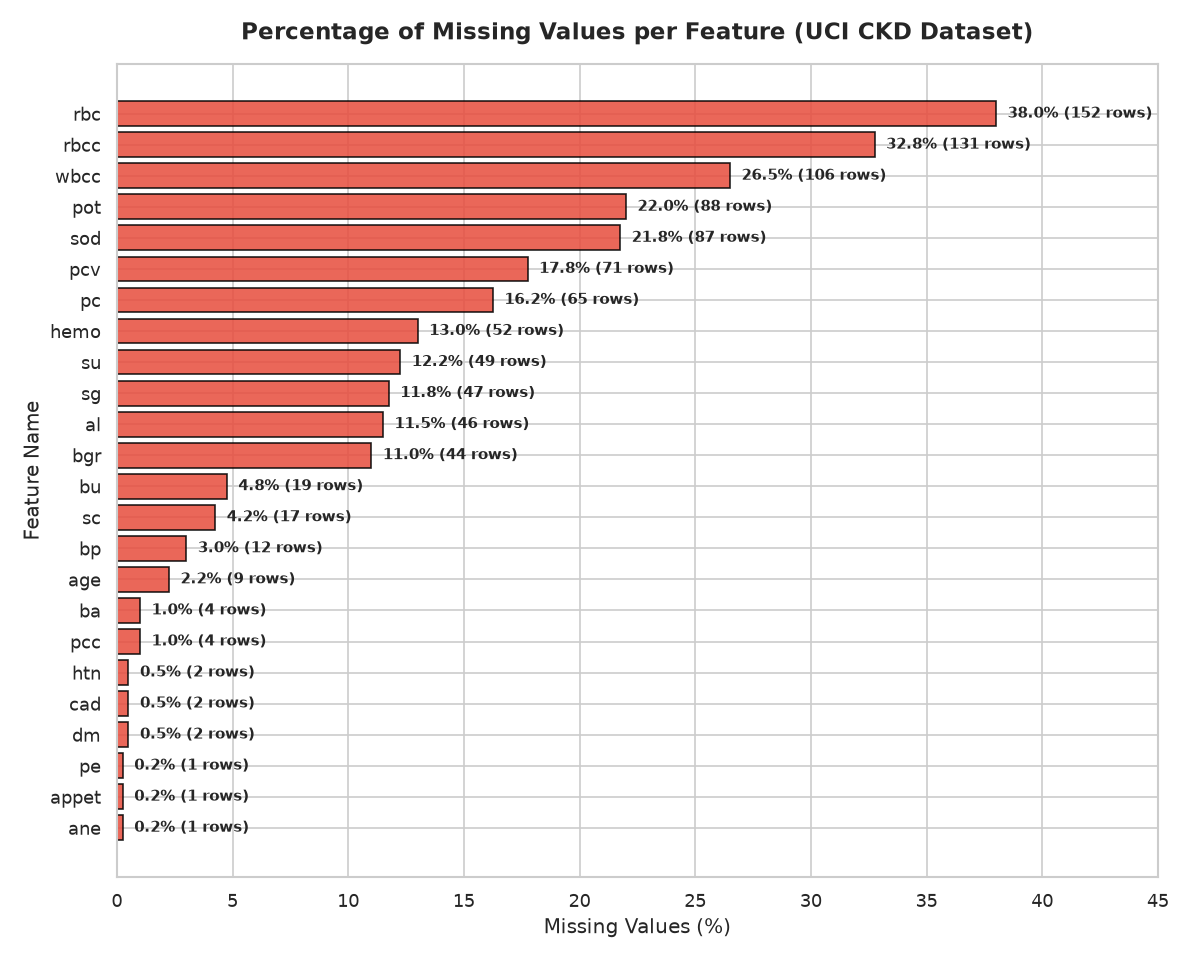

In [23]:
# Plot Missing Values Percentage
plt.figure(figsize=(10, 8))
missing_plot_data = missing_summary[missing_summary['Missing Count'] > 0].sort_values(by='Missing Percentage (%)', ascending=True)

bars = plt.barh(missing_plot_data.index, missing_plot_data['Missing Percentage (%)'], color='#e74c3c', edgecolor='black', alpha=0.85)
plt.title('Percentage of Missing Values per Feature (UCI CKD Dataset)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Missing Percentage (%)', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.xlim(0, 45)

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.5, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


**What this visualization tells us**:
- The feature with the highest missingness is **`rbc` (38.0%)**, followed by **`rbcc` (32.8%)**, **`wbcc` (26.5%)**, and electrolytes **`pot` & `sod` (~22%)**.
- Tests that are inexpensive, non-invasive, or clinically routine (such as taking blood pressure `bp`, checking age, or asking symptom questions like appetite and swelling) have minimal or near-zero missing values.
- In Stage 4, this chart informs us that we should use median/mode imputation rather than discarding columns or rows.


---
### Step 9: Visualization 2 — Target Class Distribution

**Beginner Explanation**:
- A count plot of the target variable visually demonstrates the distribution between healthy individuals and individuals with Chronic Kidney Disease.
- We also plot the uncleaned raw labels so the `'ckd\t'` formatting error is explicitly highlighted.


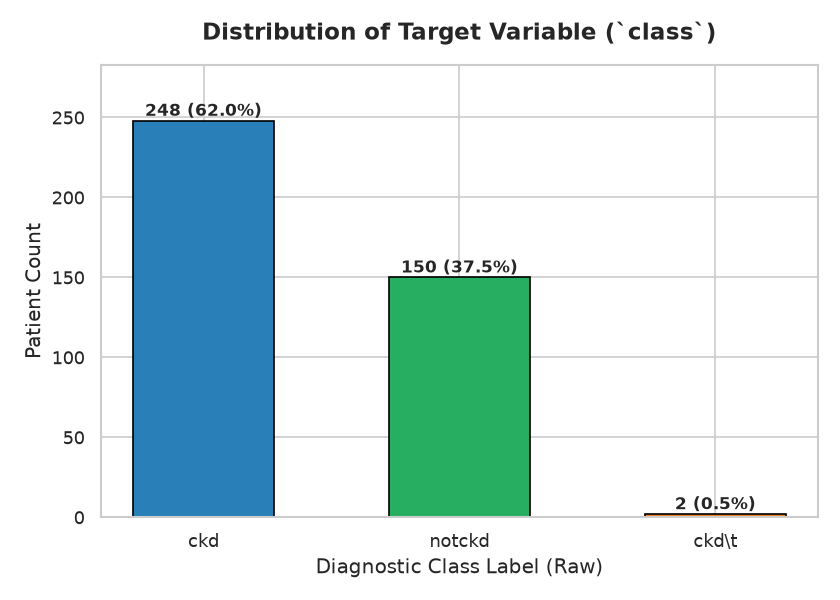

In [26]:
# Plot Target Class Distribution
plt.figure(figsize=(7, 5))
labels_clean = [f"{str(k).replace(chr(9), r'\t')}" for k in class_counts.index]
colors = ['#2980b9', '#27ae60', '#e67e22']

bars = plt.bar(labels_clean, class_counts.values, color=colors, edgecolor='black', width=0.55)
plt.title('Distribution of Target Variable (`class`)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Diagnostic Class Label (Raw)', fontsize=12)
plt.ylabel('Patient Count', fontsize=12)
plt.ylim(0, max(class_counts.values) + 35)

for bar in bars:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    plt.text(bar.get_x() + bar.get_width()/2, h + 3, f'{h} ({pct:.1f}%)', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


**What this visualization tells us**:
- **62.5% of records are positive for CKD** (250 patients) and **37.5% are negative** (150 patients).
- Because neither class is extremely rare (such as 1 in 10,000 in fraud detection), standard evaluation metrics like **Accuracy**, **Precision**, **Recall (Sensitivity)**, and **ROC-AUC** will be meaningful.
- In healthcare, **Recall (Sensitivity)** will be the most critical metric because missing a true CKD patient (False Negative) could delay life-saving medical intervention.


---
### Step 10: Visualization 3 — Numerical Feature Distributions

**Beginner Explanation**:
- A histogram shows how the values of a numeric feature are distributed across patients.
- The red dashed line marks the **median** value of each feature.
- We look for:
  1. **Skewness**: Are values clustered on one side with a long tail? (e.g. serum creatinine).
  2. **Outliers**: Are there extreme physiological values?
  3. **Bimodal distributions**: Are there two distinct patient groups?


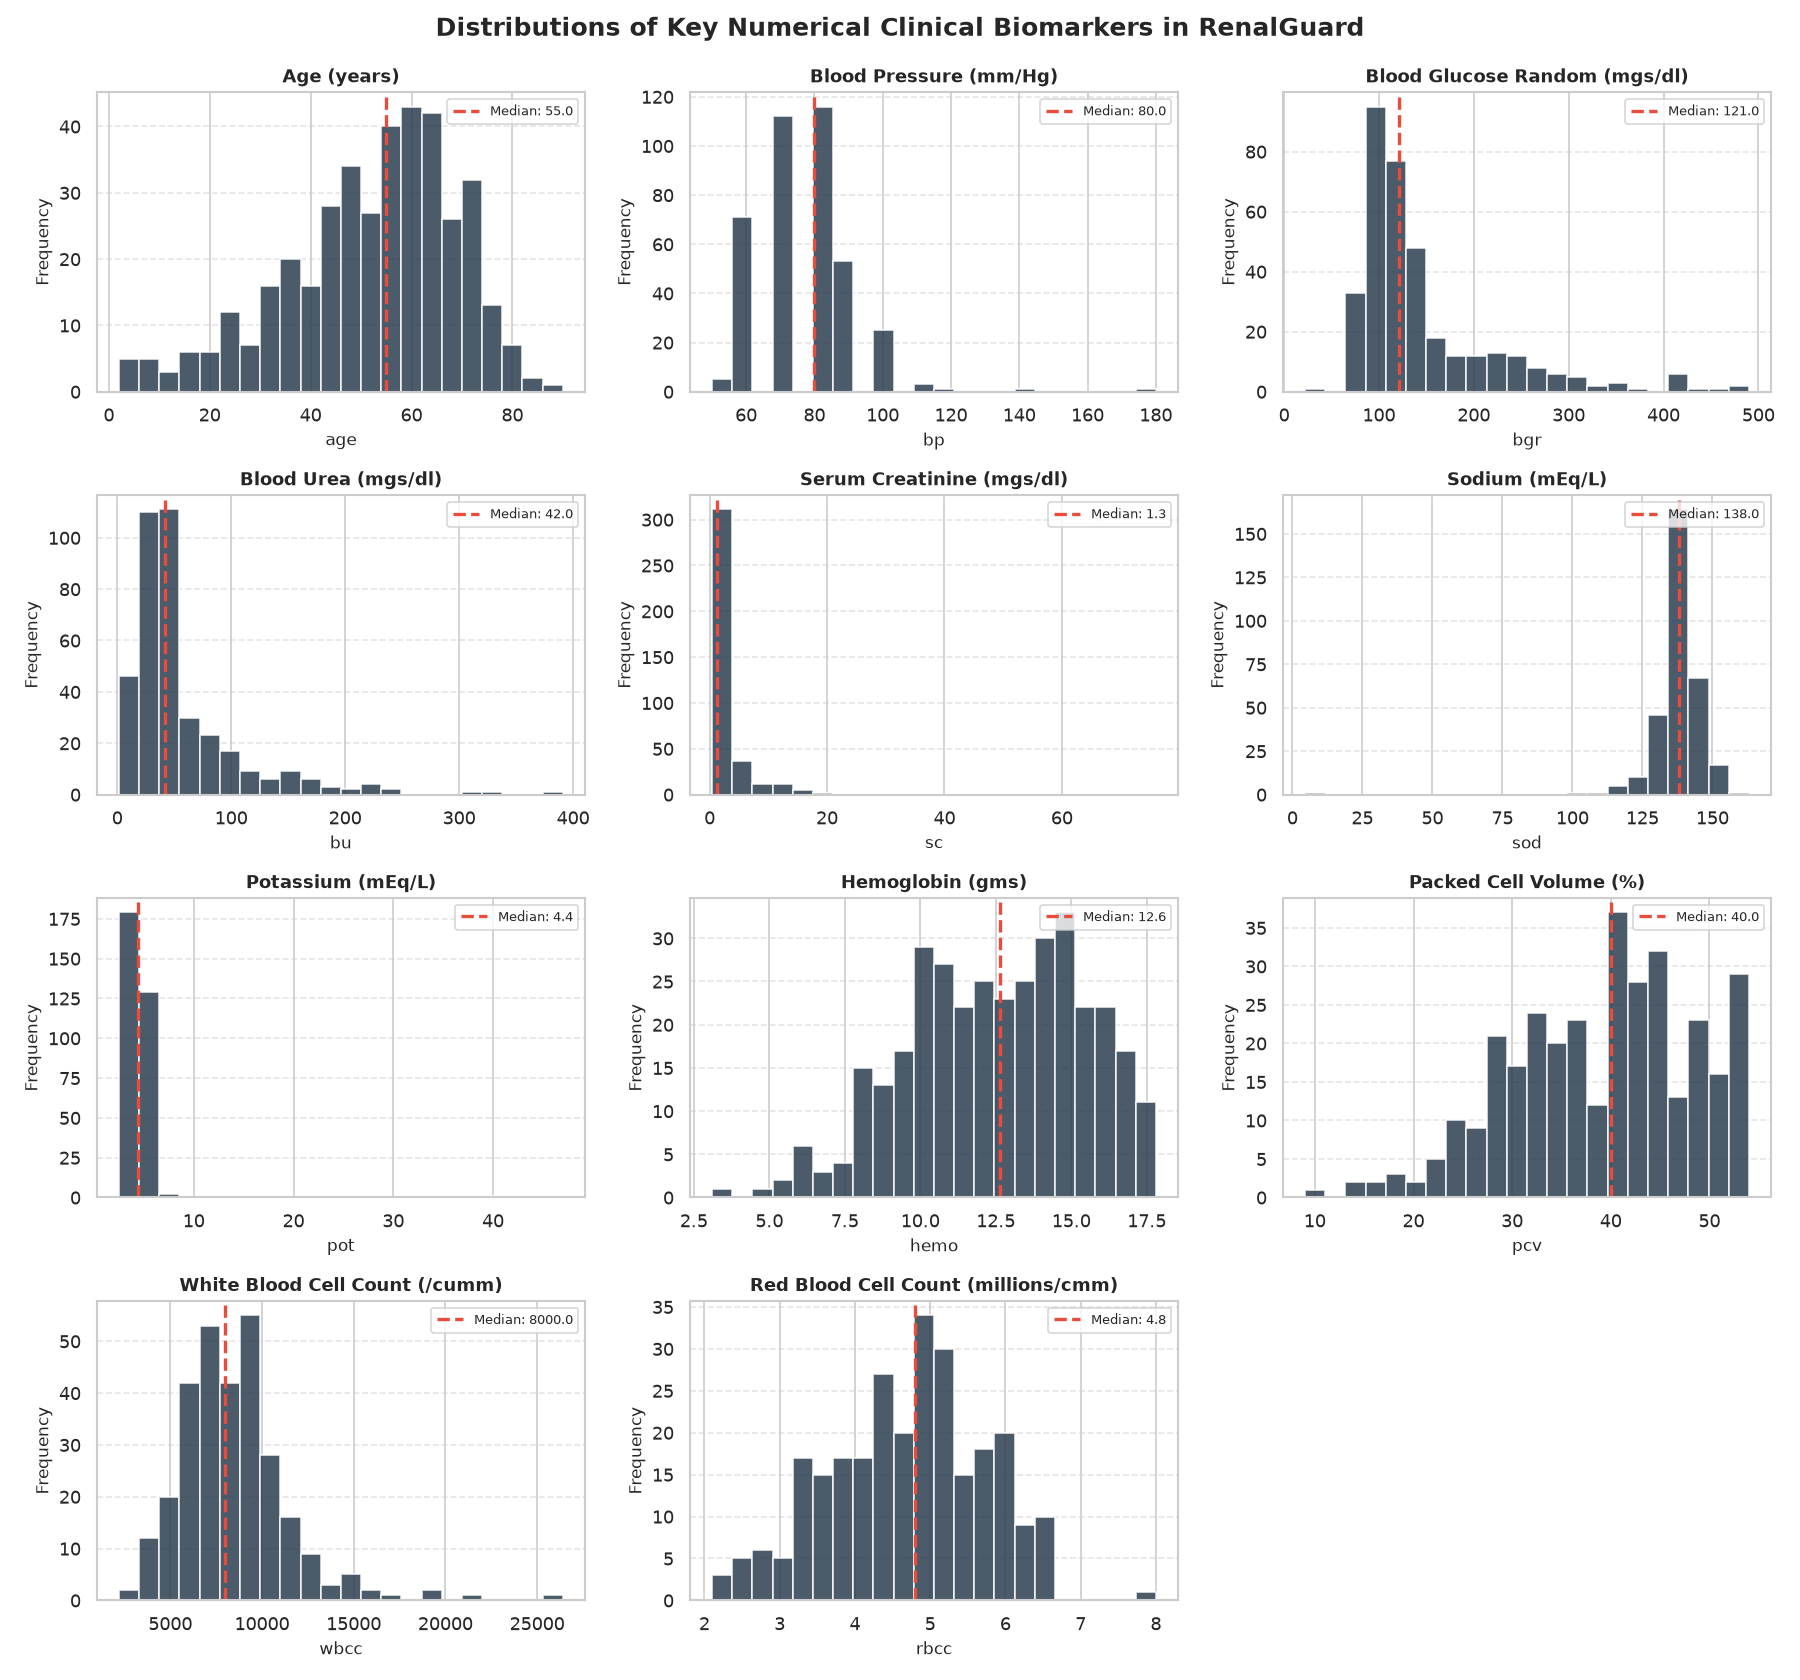

In [29]:
# Plot distributions of key numerical features
key_num_cols = ['age', 'bp', 'bgr', 'bu', 'sc', 'sod', 'pot', 'hemo', 'pcv', 'wbcc', 'rbcc']
feature_names_clinical = {
    'age': 'Age (years)',
    'bp': 'Blood Pressure (mm/Hg)',
    'bgr': 'Blood Glucose Random (mgs/dl)',
    'bu': 'Blood Urea (mgs/dl)',
    'sc': 'Serum Creatinine (mgs/dl)',
    'sod': 'Sodium (mEq/L)',
    'pot': 'Potassium (mEq/L)',
    'hemo': 'Hemoglobin (gms)',
    'pcv': 'Packed Cell Volume (%)',
    'wbcc': 'White Blood Cell Count (/cumm)',
    'rbcc': 'Red Blood Cell Count (millions/cmm)'
}

fig, axes = plt.subplots(nrows=4, ncols=3, figsize=(15, 14))
axes = axes.flatten()

for i, col in enumerate(key_num_cols):
    data = df[col].dropna()
    axes[i].hist(data, bins=22, color='#2c3e50', edgecolor='white', alpha=0.85)
    axes[i].axvline(data.median(), color='#e74c3c', linestyle='dashed', linewidth=2, label=f'Median: {data.median():.1f}')
    axes[i].set_title(feature_names_clinical.get(col, col), fontsize=11, fontweight='bold')
    axes[i].set_xlabel(col, fontsize=10)
    axes[i].set_ylabel('Frequency', fontsize=10)
    axes[i].legend(loc='upper right', fontsize=8)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)

# Remove unused 12th subplot
fig.delaxes(axes[11])
plt.suptitle('Distributions of Key Numerical Clinical Biomarkers in RenalGuard', fontsize=15, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


**What this visualization tells us (Clinical Insights)**:
1. **Serum Creatinine (`sc`) & Blood Urea (`bu`)**:
   - Both exhibit **severe right-skewness**.
   - Normal serum creatinine is 0.6–1.2 mg/dL. In healthy individuals, the median is near 1.3 mg/dL, but in patients suffering from acute kidney injury or chronic renal failure, creatinine spikes to 10, 15, and even 76 mg/dL!
   - Similarly, blood urea has extreme values up to 391 mg/dL (normal is ~7–20 mg/dL).
2. **Hemoglobin (`hemo`) & Packed Cell Volume (`pcv`)**:
   - Both show a broad distribution shifted toward low values.
   - Healthy kidneys produce erythropoietin (a hormone that stimulates red blood cell production). As kidney function declines, hemoglobin levels drop severely (down to 3.1 g/dL in some patients), causing **renal anemia**.
3. **Blood Glucose Random (`bgr`)**:
   - Notice the long right tail extending to 490 mg/dL. Diabetes mellitus is one of the leading causes of kidney failure worldwide (diabetic nephropathy).
4. **Blood Pressure (`bp`)**:
   - Clustered around 70–80 mm/Hg, with hypertensive peaks at 100–180 mm/Hg. Hypertension is both a cause and a consequence of CKD.


---
## Summary of Dataset Condition & Next Preprocessing Steps

### 1. Dataset Health Summary
- **Sample Size**: 400 patient records with 24 predictors and 1 target variable.
- **Completeness**: Extensive missing values across lab measurements (up to 38% in urinalysis microscopy). **Crucially, no rows should be dropped**, as this would eliminate over 60% of patients.
- **Duplicates**: 0 duplicates found.
- **Target Distribution**: 250 CKD positive cases (62.5%) vs 150 non-CKD cases (37.5%).
- **Data Quality Anomalies**:
  - Trailing tab typo in target column: `'ckd\t'` must be cleaned to `'ckd'`.
  - Leading/trailing whitespace or tabs in categorical features (e.g. `'\tno'` in diabetes `dm`).
  - Extreme biological outliers in `sc` (creatinine) and `bu` (blood urea).

---

### 2. Recommended Next Preprocessing Steps (For Stage 4)

1. **Target Label Cleaning & Binary Encoding**:
   - Strip whitespace and tab characters from `class`.
   - Map `'ckd'` $\rightarrow$ `1` and `'notckd'` $\rightarrow$ `0`.
2. **Categorical Feature Cleaning & Encoding**:
   - Clean whitespace anomalies in categorical columns (e.g. `dm`, `cad`).
   - Binary encode nominal 2-class variables (`yes`/`no` $\rightarrow$ `1`/`0`, `normal`/`abnormal` $\rightarrow$ `1`/`0`).
   - One-hot encode or ordinal encode multi-category variables.
3. **Missing Value Imputation**:
   - **Numerical Features**: Use **Median Imputation** (more robust to extreme clinical outliers than mean).
   - **Categorical Features**: Use **Most Frequent (Mode) Imputation**.
4. **Feature Scaling**:
   - Use `RobustScaler` or `StandardScaler` on numerical features so algorithms like Logistic Regression, SVM, and Neural Networks are not dominated by the large scales of `bgr` or `wbcc`.
5. **Train / Test Splitting**:
   - Use stratified sampling (`StratifiedKFold` or `train_test_split(..., stratify=y)`) to ensure train and test sets preserve the 62.5% / 37.5% clinical class ratio.
